# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [x] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [x] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice (TF-IDF and frozen `Qwen/Qwen3-Embedding-0.6B`).
    - [x] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (two-hidden-layer MLP, `TwoLayerSparseMLP`).
- [x] Your comparisons must be based on cross-validation and a relevant metric (accuracy, alongside macro precision, macro recall, and macro F1).
- [x] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to six slides (one for each of the topics/questions in the 'Get to work!' section); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

## Design decisions and why

For the oral and the blog post. Edit here if a choice changes.

| Topic | Decision | Reason |
|---|---|---|
| Dataset | IMDB (`mteb/imdb`): 24,904 training reviews, 2 classes, about 50/50 (12,432 negative / 12,472 positive). | Balanced labels (49.92% / 50.08%), so accuracy is a fair main metric; macro precision, macro recall, and macro F1 are reported as well. |
| Preprocessing | Strip HTML tags, decode HTML entities, collapse whitespace, lowercase except ALL-CAPS words; original text kept in `text_original`. | Removes markup noise (e.g. `<br />`) while keeping emphasis such as AWFUL as a distinct token. |
| Validation / test | 2,000 random reviews from the original IMDB test split (seed 0) are the validation set; the other 22,678 are the new test set. | Hyperparameter tuning needs data that is neither training nor final test. Indices saved in `results/sentiment/`. The new test set is not used for tuning. |
| Tokenizer | One BPE tokenizer trained on the preprocessed training reviews only, vocab size 5000, min frequency 2, shared by all BPE representations. | Same tokens for every BPE representation, so they differ only in weighting. Vocab 5000 won on the validation set (logistic + bag-of-words): 1000 → 0.8245, 5000 → 0.8580, 8000 → 0.8510, 16000 → 0.8550. The standard error is about 0.8 points, so 5000, 8000 and 16000 are practically tied; ties go to the smaller vocabulary. |
| Representations (4) | Token indicators and bag-of-words (tutorial) plus **TF-IDF** (BPE 5,000) and frozen **`Qwen/Qwen3-Embedding-0.6B`** (1,024-d dense embeddings). | TF-IDF down-weights ubiquitous tokens and L2-normalises review length. Qwen-0.6B provides a contextual pretrained transformer baseline to contrast against bag-of-tokens representations. |
| Architectures (3) | Log-linear (scikit-learn `saga`, `max_iter=100`), 1-hidden-layer MLP (`SparseMLP`: 128 hidden, dropout 0.1, batch 64, lr 1e-4, weight decay 1e-4), and **2-hidden-layer MLP** (`TwoLayerSparseMLP`: two 128-unit ReLU + dropout 0.1 layers). | Tests linear vs. shallow non-linear vs. deeper non-linear classifiers across all 4 representations (12 configurations total). |
| MLP epochs | Up to 50 epochs with early stopping (patience 5, min_delta 0.001 on validation loss); best-validation-loss checkpoint kept. | Our folds have ~19.9k reviews (~312 steps per epoch) vs ~96k per tutorial fold (~1,500 steps per epoch), so 50 epochs matches the ~15.6k step budget of the tutorial while early stopping prevents unnecessary compute and overfitting. |
| Cross-validation | 5 folds, seeds 42 and 67 (two runs with different fold shuffles = 10 paired fold measurements per system); every system uses the exact same splits. | The Bayesian correlated $t$-test pairs folds across systems and accounts for overlap correlation ($\rho \approx 1/k$). |
| Metrics | Accuracy (primary), macro precision, macro recall, and macro F1 per validation fold. | Because classes are balanced (50/50) and symmetric in importance, accuracy weights all four confusion-matrix cells equally, whereas binary F1 ignores true negatives. |
| Bayesian ROPE | `rope_param = 0.005` (0.5 percentage points of accuracy, $\approx 25$ reviews per 4,981-review validation fold). | Matches the tutorial's practical significance threshold and reflects a difference of roughly 25 reviews per fold—smaller differences are indistinguishable from split noise. |
| Reproducibility | Fixed seeds; results saved per system and seed in `results/sentiment/` (re-running a cell loads saved results); small artefacts are git-tracked, model files are not. | Experiments are shared with the blog post and reused in projects 2 and 3. |

# Load dataset 

In [1]:
import pandas as pd


splits = {'train': 'data/train-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
df = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["train"])

In [2]:
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
}))

print(f"Reviews: {len(df):,}")
print(f"Duplicate review texts: {df['text'].duplicated().sum():,}")
print(f"Empty reviews: {df['text'].fillna('').str.strip().eq('').sum():,}")

class_balance = (
    df.groupby(["label", "label_text"])
    .size()
    .rename("count")
    .to_frame()
)
class_balance["percent"] = (100 * class_balance["count"] / len(df)).round(2)
display(class_balance)

,dtype,missing
text,str,0
label,int64,0
label_text,str,0


Reviews: 24,904
Duplicate review texts: 0
Empty reviews: 0


,,count,percent
label,label_text,,
0,negative,12432,49.92
1,positive,12472,50.08


characters                    words                 
                mean median min    max   mean median min   max
sentiment                                                     
negative      1304.2  977.0  52   8969  231.1  175.0  10  1522
positive      1348.5  982.0  70  13704  236.9  174.0  12  2470

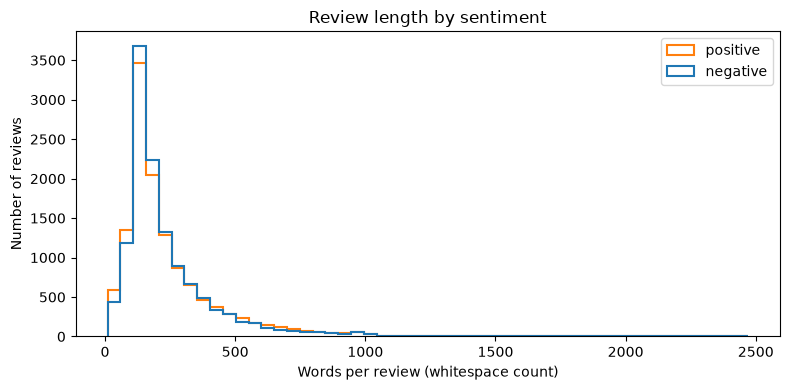

In [3]:
import matplotlib.pyplot as plt

review_lengths = pd.DataFrame({
    "sentiment": df["label_text"],
    "characters": df["text"].fillna("").str.len(),
    "words": df["text"].fillna("").str.split().str.len(),
})

display(
    review_lengths.groupby("sentiment")[["characters", "words"]]
    .agg(["mean", "median", "min", "max"])
    .round(1)
)

groups = list(review_lengths.groupby("sentiment"))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    [group["words"] for _, group in groups],
    bins=50,
    histtype="step",
    linewidth=1.5,
    label=[sentiment for sentiment, _ in groups],
)
ax.set(
    title="Review length by sentiment",
    xlabel="Words per review (whitespace count)",
    ylabel="Number of reviews",
)
ax.legend()
plt.tight_layout()
plt.show()

In [4]:
# Inspect the shortest and longest cleaned reviews by whitespace word count.
review_sizes = df[["text", "label_text"]].assign(
    word_count=df["text"].fillna("").str.split().str.len()
)

for title, reviews in [
    ("5 shortest reviews", review_sizes.nsmallest(5, "word_count")),
    ("5 longest reviews", review_sizes.nlargest(5, "word_count")),
]:
    print(f"\n{title}\n" + "=" * len(title))
    for index, row in reviews.iterrows():
        print(f"\nRow {index} | {row['label_text']} | {row['word_count']} words")
        print(row["text"])


5 shortest reviews

Row 2401 | negative | 10 words
I wouldn't rent this one even on dollar rental night.

Row 10872 | negative | 10 words
This movie is terrible but it has some good effects.

Row 372 | negative | 11 words
You'd better choose Paul Verhoeven's even if you have watched it.

Row 12053 | negative | 12 words
Ming The Merciless does a little Bardwork and a movie most foul!

Row 16993 | positive | 12 words
Adrian Pasdar is excellent is this film. He makes a fascinating woman.

5 longest reviews

Row 13685 | positive | 2470 words
Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag Team Table Match against Eddie Guerrero and Chris Benoit. According to the rules of the match, both opponents have to go through tables in order to get the win. Benoit and Guerrero heated up early on by taking turns hammering first Spike and then Bubba Ray. A German suplex by Benoit to Bubba took the wind

We replace HTML tags with spaces, decode HTML entities, and collapse repeated whitespace. Words are lowercased (e.g., `Read` → `read`), except all-caps words such as `AWFUL`, which retain their emphasis. The original reviews are preserved in `text_original`, while `text` contains the normalized reviews.

In [5]:
import re
from html.parser import HTMLParser


class ReviewHTMLParser(HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []

    def handle_starttag(self, tag, attrs):
        self.parts.append(" ")

    def handle_endtag(self, tag):
        self.parts.append(" ")

    def handle_data(self, data):
        self.parts.append(data)


def normalize_review(text):
    parser = ReviewHTMLParser()
    parser.feed(text)
    parser.close()
    text = "".join(parser.parts)
    text = re.sub(
        r"[^\W\d_]+(?:['’][^\W\d_]+)*",
        lambda match: match[0] if match[0].isupper() else match[0].lower(),
        text,
    )
    return " ".join(text.split())


if "text_original" not in df.columns:
    df["text_original"] = df["text"].copy()
df["text"] = df["text_original"].map(normalize_review, na_action="ignore")
display(df[["text_original", "text"]].head(3))


,text_original,text
0,I rented I AM CURIOUS-YELLOW from my video sto...,I rented I AM CURIOUS-YELLOW from my video sto...
1,"""I Am Curious: Yellow"" is a risible and preten...","""I am curious: yellow"" is a risible and preten..."
2,If only to avoid making this type of film in t...,if only to avoid making this type of film in t...


## Validation and test sets

We hold out **2,000 random reviews from the original IMDB test split** as a validation set for tuning (the BPE vocabulary size below). The remaining test reviews form the **new test set** (`df_test`), which is never used for tuning. Both are preprocessed with the same `normalize_review` as the training data, and the original test-row indices of both sets are saved in `results/sentiment/` so the split is reproducible.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 0
N_VALIDATION = 2000

df_test_original = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["test"])

# Validation: 2,000 random test reviews. New test set: all the other test reviews.
# Both keep the original test-row index, so they can be traced back to the source split.
df_val = df_test_original.sample(n=N_VALIDATION, random_state=SEED).sort_index()
df_test = df_test_original.drop(index=df_val.index)

# Same preprocessing as the training reviews (normalize_review comes from the preprocessing cell).
df_val = df_val.assign(text_original=df_val["text"], text=df_val["text"].map(normalize_review))
df_test = df_test.assign(text_original=df_test["text"], text=df_test["text"].map(normalize_review))

split_dir = Path("results/sentiment")
split_dir.mkdir(parents=True, exist_ok=True)
np.save(split_dir / "validation_test_indices.npy", df_val.index.to_numpy())
np.save(split_dir / "new_test_indices.npy", df_test.index.to_numpy())

# Sanity checks: nothing lost, no overlap, balanced labels, no train/validation/test text leakage.
assert len(df_val) + len(df_test) == len(df_test_original)
assert df_val.index.intersection(df_test.index).empty
train_texts = set(df["text"])
print(f"Train: {len(df):,} | validation: {len(df_val):,} | new test: {len(df_test):,}")
for name, part in [("validation", df_val), ("new test", df_test)]:
    print(f"{name}: labels {part['label'].value_counts().sort_index().to_dict()}, "
          f"texts also in train: {part['text'].isin(train_texts).sum()}")
print(f"texts in both validation and new test: {df_val['text'].isin(set(df_test['text'])).sum()}")


Train: 24,904 | validation: 2,000 | new test: 22,678
validation: labels {0: 974, 1: 1026}, texts also in train: 0
new test: labels {0: 11292, 1: 11386}, texts also in train: 0


texts in both validation and new test: 0


## Choosing the BPE vocabulary size

We choose the vocabulary size on the 2,000-review validation set prepared above. For each candidate size we train a BPE tokenizer on the preprocessed training reviews, fit the tutorial's logistic regression (saga, `max_iter=100`) on bag-of-words counts of the training reviews, and measure accuracy on the validation reviews. Only the vocabulary size changes between runs. The best size is then used for the tokenizer in the rest of the notebook.

Notes for the oral:
- Accuracy is fine as the metric because the labels are balanced (about 50/50).
- With 2,000 reviews the standard error of an accuracy near 0.88 is about 0.7 points, so differences smaller than that are not meaningful; ties go to the smaller vocabulary.
- The bag-of-words matrix is built sparsely here (same counts as the tutorial's `BagOfWords`) because `loglin.fit` builds a dense matrix first, which would need several GB at vocabulary 16,000.
- Only the results table (`results/sentiment/vocab_size_tuning.csv`) is saved; the candidate tokenizers and logistic models are discarded. Only the chosen tokenizer is trained and saved, in the next section.

In [7]:
# THIS IS COMMENTED OUT TO NOT ALWAYS RUN THE HYPERPARAMTER TUNNING. IF YOU WANT, YOU CAN RUN IT AND SEE THAT 5000 IS THE BEST

# import sys
# import warnings
# from pathlib import Path

# import numpy as np
# import pandas as pd
# from scipy.sparse import csr_matrix
# from sklearn.exceptions import ConvergenceWarning
# from sklearn.linear_model import LogisticRegression

# sys.path.insert(0, str(Path.cwd().parent))  # run with part1/ as working directory
# import part1

# # Uses df (train), df_val (validation) and SEED from the cells above.
# CANDIDATE_VOCAB_SIZES = [1000, 5000, 8000, 16000]
# TOKENIZER_MIN_FREQ = 2  # held fixed; only the vocabulary size is tuned


# def bow_matrix(tokenizer, texts):
#     """Bag-of-words counts (one column per BPE token) as a sparse matrix.

#     Same representation as the tutorial's BagOfWords, but built sparsely: loglin.fit goes through
#     a dense matrix, which is about 6 GB at vocabulary 16,000 and 25k reviews.
#     """
#     rows, cols, vals = [], [], []
#     for i, enc in enumerate(tokenizer.encode_batch(list(texts))):
#         ids, counts = np.unique(enc.ids, return_counts=True)
#         rows.append(np.full(len(ids), i))
#         cols.append(ids)
#         vals.append(counts)
#     return csr_matrix(
#         (np.concatenate(vals).astype(np.float64), (np.concatenate(rows), np.concatenate(cols))),
#         shape=(len(texts), len(tokenizer.get_vocab())),
#     )


# # --- One tokenizer + one logistic regression per candidate size; everything else is fixed ---
# y_train, y_val = df["label"].to_numpy(), df_val["label"].to_numpy()
# vocab_results = []
# for vocab_size in CANDIDATE_VOCAB_SIZES:
#     candidate = part1.experiment.train_tokenizer(
#         df["text"].tolist(), vocab_size=vocab_size, min_frequency=TOKENIZER_MIN_FREQ
#     )
#     X_train, X_val = bow_matrix(candidate, df["text"]), bow_matrix(candidate, df_val["text"])

#     # Same settings as loglin.fit, plus a fixed random_state: saga shuffles the data, so without it
#     # the accuracies change slightly from run to run.
#     model = LogisticRegression(solver="saga", max_iter=100, random_state=SEED)
#     with warnings.catch_warnings():
#         warnings.simplefilter("ignore", ConvergenceWarning)  # reported below via n_iter instead
#         model.fit(X_train, y_train)

#     val_accuracy = float((model.predict(X_val) == y_val).mean())
#     vocab_results.append({
#         "vocab_size": vocab_size,
#         "actual_vocab": len(candidate.get_vocab()),
#         "val_accuracy": val_accuracy,
#         "std_error": (val_accuracy * (1 - val_accuracy) / len(y_val)) ** 0.5,
#         "train_accuracy": float((model.predict(X_train) == y_train).mean()),
#         "saga_iterations": int(model.n_iter_[0]),  # == 100 means the iteration cap was hit (not converged)
#         "tokens_per_review": X_train.sum() / X_train.shape[0],
#     })
#     print(f"vocab {vocab_size}: validation accuracy {val_accuracy:.4f}")

# vocab_results = pd.DataFrame(vocab_results).set_index("vocab_size")
# display(vocab_results.round(4))
# vocab_results.to_csv("results/sentiment/vocab_size_tuning.csv")  # the candidate tokenizers/models are not kept

# best_vocab_size = int(vocab_results["val_accuracy"].idxmax())  # ties -> first = smallest vocabulary
# print(f"\nBest vocabulary size on the 2,000 validation reviews: {best_vocab_size}")


## BPE tokenizer

One BPE tokenizer, trained on the **preprocessed** IMDB training reviews (`df["text"]`, after the normalisation above), is shared by every representation (token indicators, bag-of-words, TF-IDF), so the representations differ only in how they weight the same tokens. Training uses no labels. It is saved under `results/sentiment/` so it can be reloaded instead of retrained.

In [8]:
import sys
from pathlib import Path

from tokenizers import Tokenizer

sys.path.insert(0, str(Path.cwd().parent))  # run with part1/ as working directory
import part1

# Vocabulary size chosen on the 2,000 held-out validation reviews (previous section);
# TOKENIZER_MIN_FREQ (also defined there) was held fixed at 2 as in the tutorial.
TOKENIZER_VOCAB_SIZE = 5000 #best_vocab_size
TOKENIZER_MIN_FREQ = 2

tokenizer_path = Path("results/sentiment") / f"BPE_tokenizer_imdb_vs_{TOKENIZER_VOCAB_SIZE}_mf_{TOKENIZER_MIN_FREQ}.json"
tokenizer_path.parent.mkdir(parents=True, exist_ok=True)

if tokenizer_path.exists():
    tokenizer = Tokenizer.from_file(str(tokenizer_path))  # reload: identical tokenizer across sessions
else:
    assert "text_original" in df.columns, "Run the preprocessing cell first: train on the normalised text."
    tokenizer = part1.experiment.train_tokenizer(
        df["text"].tolist(),
        vocab_size=TOKENIZER_VOCAB_SIZE,
        min_frequency=TOKENIZER_MIN_FREQ,
    )
    tokenizer.save(str(tokenizer_path))

print(len(tokenizer.get_vocab()), "tokens;", tokenizer_path)
print(tokenizer.encode(df["text"].iloc[1]).tokens[:20])


5000 tokens; results/sentiment/BPE_tokenizer_imdb_vs_5000_mf_2.json
['▁"I', '▁am', '▁curious', ':', '▁ye', 'llow', '"', '▁is', '▁a', '▁ris', 'ible', '▁and', '▁pretent', 'ious', '▁ste', 'am', 'ing', '▁p', 'ile', '.']


## Tf-idf embedding

In [9]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

from part1.clslib import Encoder


class TfidfEncoder(Encoder):
    """scikit-learn TF-IDF over our BPE tokens, behind the tutorial's Encoder interface.

    The vectorizer's analyzer returns BPE token ids, so scikit-learn does the weighting
    (raw count * smoothed idf, L2-normalised per document) but not the tokenisation.
    `vocabulary` is fixed to all tokenizer ids so the dimensionality equals the
    tokenizer's vocabulary size, identical to TokenIndicator and BagOfWords.
    """

    def __init__(self, tokenizer, texts):
        self.tokenizer = tokenizer
        texts_list = list(texts)
        self.vectorizer = TfidfVectorizer(
            analyzer=lambda text: tokenizer.encode(text).ids,
            vocabulary=range(len(tokenizer.get_vocab())),
            lowercase=False,
            dtype=np.float32,
        )
        X_tfidf = self.vectorizer.fit_transform(texts_list)
        self._cache = {t: X_tfidf[i].toarray()[0] for i, t in enumerate(texts_list)}

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vec = self._cache.get(x)
        if vec is None:
            vec = self.vectorizer.transform([x]).toarray()[0]
            self._cache[x] = vec
        return vec


# Uses the shared BPE tokenizer from the "BPE tokenizer" cell above (same one as the other encoders).
tfidf_encoder = TfidfEncoder(tokenizer, df["text"])

# Sanity checks.
example = tfidf_encoder(df["text"].iloc[0])
print(len(tfidf_encoder), len(example), np.linalg.norm(example), (example > 0).sum(), "non-zero dims")

5000 5000 1.0 246 non-zero dims


In [10]:

idx = np.nonzero(tfidf_encoder("hello i am alex!"))[0]
idx

array([   3,   81,  399,  443, 1908, 3442])

In [11]:
# Optional: uncomment and run once only if these dependencies are missing.
# %pip install 'sentence-transformers>=2.7.0' 'transformers>=4.51.0'


## Cross-validation of the tutorial systems (token indicators and bag-of-words)

The tutorial's four systems, rerun on IMDB with the shared BPE tokenizer: {log-linear, one-hidden-layer MLP} x {token indicators, bag-of-words}. The code is copied from the tutorial and reuses `part1.experiment.cross_validation_experiment`, `part1.loglin` and `part1.smlp` (with the two small optional additions listed below), with the hyperparameters from the tutorial (logistic: `max_iter=100`; MLP: 128 hidden units, dropout 0.1, batch 64, lr 1e-4, weight decay 1e-4), except for the number of epochs. Changes to `part1`: an optional `random_state` in `loglin.fit` (reproducible logistic runs) and optional early stopping (`patience`, `min_delta`) in `smlp.train_neural_network_model`; both default to the tutorial's behaviour.

- **Epochs**: AG News has 120k texts (about 96k per training fold, ~1,500 steps per epoch at batch 64), so 10 epochs were ~15k optimiser steps. Our folds have ~19.9k reviews (~312 steps per epoch), so 10 epochs would be only ~3k steps and likely undertrained. We allow up to 50 epochs (~15.6k steps, the same number of steps as the tutorial).
- **Early stopping**: training stops when the validation loss has not improved by more than 0.001 for 5 epochs in a row, and the checkpoint with the lowest validation loss is kept (as in the tutorial). So 50 is only a cap. Note that both the checkpoint and the stopping point are chosen on the fold being scored, which is mildly optimistic, and identically so for all MLPs.
- **Seeds**: 42 and 67, i.e. two cross-validation runs with different fold shuffles (10 accuracies per system for the Bayesian test).
- **Same folds for every system**: the Bayesian test pairs folds, so all systems use `my_cross_validation_sets` (training reviews only; `df_val` and `df_test` are not touched).
- **Metrics**: accuracy, macro recall and macro F1 are computed on each validation fold. With balanced labels accuracy is the main metric; macro recall equals balanced accuracy for two classes.
- **Saving**: each run is stored in `results/sentiment/<system>/seed-<seed>/` (models per fold plus `results.json` with predictions and per-fold metrics). If `results.json` exists, `run_system` loads it instead of retraining, so re-running a cell is cheap. Delete the folder to retrain.
- **Cost**: the tutorial needed about 3 minutes per logistic run and about 20 minutes per MLP run (10 epochs, AG News). Ours have fewer but longer texts and up to 5x more epochs, and there are two seeds, so expect it to be much longer. Nothing here runs until you execute the cells below.


In [12]:
import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from tokenizers import Tokenizer

import part1
from part1.clslib import Encoder

# --- Experimental setup, as in the tutorial but on our data ---
sentiment_outcome_space = part1.clslib.NamedClasses(['negative', 'positive'])  # labels 0 / 1 in mteb/imdb
results_folder = Path("results/sentiment")  # separate from the tutorial's AG News runs
my_seeds = [42, 67]  # two cross-validation runs, each with its own fold shuffle (the tutorial used [0])
num_folds = 5

# Every system is evaluated on the SAME folds (the Bayesian test pairs folds).
# Cross-validation uses the training reviews only; df_val and df_test are not used here.
my_cross_validation_sets = [
    part1.experiment.cross_validation_split(
        pairs=list(zip(df["text"], df["label"])),
        k=num_folds,
        seed=seed,
    )
    for seed in my_seeds
]


# --- Encoders, copied from the tutorial (with per-text memoisation to avoid redundant BPE calls across folds) ---
class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self._cache = {}

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        vector = self._cache.get(x)
        if vector is None:
            unique_token_ids = list(set(self.tokenizer.encode(x).ids))
            vector = np.zeros(len(self), dtype=np.float32)
            vector[unique_token_ids] = 1.0
            self._cache[x] = vector
        return vector


class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self._cache = {}

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        vector = self._cache.get(x)
        if vector is None:
            token_ids = self.tokenizer.encode(x).ids
            counts = Counter(token_ids)
            vector = np.zeros(len(self), dtype=np.float32)
            for idx, count in counts.items():
                vector[idx] = count
            self._cache[x] = vector
        return vector


token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
print(len(token_indicator_encoder), len(bow_encoder), "dimensions;", num_folds, "folds x", len(my_seeds), "run(s) with seeds", my_seeds)

5000 5000 dimensions; 5 folds x 2 run(s) with seeds [42, 67]


In [13]:
# Hyperparameters of the tutorial's systems, except the number of epochs and early stopping.
LOGISTIC_ARGS = {'max_iter': 100}
MLP_ARGS = {
    'hidden_dim': 128,
    'dropout': 0.1,
    'batch_size': 64,
    'learning_rate': 1e-4,
    'weight_decay': 1e-4,
    'num_epochs': 50,   # maximum; the tutorial used 10 on 5x more data per fold (see the markdown above)
    'patience': 5,      # early stopping: stop after 5 epochs without a validation-loss improvement...
    'min_delta': 1e-3,  # ...larger than 0.001 (loss values here are around 0.3 to 0.7)
}
MLP2_ARGS = {
    **MLP_ARGS,
    'hidden_layers': 2,  # two-hidden-layer MLP (TwoLayerSparseMLP in part1.smlp)
}

my_classifiers = {}  # system name -> list with one result dict per seed (same shape as in the tutorial)


def fold_metrics(gold, predicted):
    """Accuracy, macro precision, macro recall and macro F1 of one validation fold."""
    return {
        'accuracy': accuracy_score(gold, predicted),
        'precision': precision_score(gold, predicted, average='macro'),
        'recall': recall_score(gold, predicted, average='macro'),
        'f1': f1_score(gold, predicted, average='macro'),
    }


def load_run(results_file):
    """Load a run saved by run_system (fold keys are integers again)."""
    saved = json.loads(results_file.read_text(encoding='utf-8'))
    per_fold = lambda key: {int(fold): value for fold, value in saved[key].items()}
    return {
        'models': per_fold('models'),
        'predictions': {fold: np.array(p) for fold, p in per_fold('predictions').items()},
        'accuracies': per_fold('accuracies'),
        'precisions': per_fold('precisions'),
        'recalls': per_fold('recalls'),
        'f1s': per_fold('f1s'),
    }


def run_system(name, encoder, model_option, model_args):
    """Cross-validate one system (one run per seed in my_seeds) and save everything it produces.

    name: folder name, e.g. 'logistic_bow-enc'; model_option: 'logistic' or 'mlp';
    model_args: loglin_args (logistic) or smlp_args (mlp), as in the tutorial.
    Per seed, results go to results/sentiment/<name>/seed-<seed>/ : the fold models (written by
    cross_validation_experiment) and results.json with predictions, validation ids and per-fold metrics.
    If results.json already exists it is loaded instead of retraining.
    """
    runs = []
    for run, seed in enumerate(my_seeds):
        run_folder = results_folder / name / f"seed-{seed}"
        results_file = run_folder / "results.json"
        args = {**model_args, 'random_state': seed} if model_option == 'logistic' else dict(model_args)

        if results_file.exists():
            saved = json.loads(results_file.read_text(encoding='utf-8'))
            if saved['args'] != args or saved['num_folds'] != num_folds:
                raise ValueError(f"{results_file} was produced with different settings; use a new name or delete the folder.")
            print(f"{name} seed {seed}: loaded saved results from {results_file}")
            runs.append(load_run(results_file))
            continue

        torch.manual_seed(seed)  # MLP weight initialisation and batch shuffling
        splits_for_run = my_cross_validation_sets[run]
        result = part1.experiment.cross_validation_experiment(
            data_splits=splits_for_run,
            outcome_space=sentiment_outcome_space,
            encoder=encoder,
            model_option=model_option,
            save_to=str(run_folder),
            **{'loglin_args' if model_option == 'logistic' else 'smlp_args': args},
        )

        # Precision, recall and F1 from the validation predictions (accuracy is already in result['accuracies']).
        gold = {fold: [label for _, label in split['validation']] for fold, split in splits_for_run.items()}
        metrics = {fold: fold_metrics(gold[fold], result['predictions'][fold]) for fold in result['predictions']}
        for fold, m in metrics.items():
            assert np.isclose(m['accuracy'], result['accuracies'][fold]), "accuracy mismatch"
        result['precisions'] = {fold: m['precision'] for fold, m in metrics.items()}
        result['recalls'] = {fold: m['recall'] for fold, m in metrics.items()}
        result['f1s'] = {fold: m['f1'] for fold, m in metrics.items()}

        results_file.write_text(json.dumps({
            'system': name, 'seed': seed, 'model_option': model_option, 'args': args,
            'encoder': type(encoder).__name__, 'vocab_size': len(encoder), 'num_folds': num_folds,
            'models': {f: str(p) for f, p in result['models'].items()},
            'accuracies': {f: float(v) for f, v in result['accuracies'].items()},
            'precisions': {f: float(v) for f, v in result['precisions'].items()},
            'recalls': {f: float(v) for f, v in result['recalls'].items()},
            'f1s': {f: float(v) for f, v in result['f1s'].items()},
            'predictions': {f: [int(p) for p in preds] for f, preds in result['predictions'].items()},
            'validation_ids': {f: [int(i) for i in split['validation_ids']] for f, split in splits_for_run.items()},
        }), encoding='utf-8')
        runs.append(result)
    return runs


def summarise(classifiers):
    """Mean and standard deviation over all folds and runs of each system's accuracy, precision, recall and F1."""
    rows = {}
    for name, runs in classifiers.items():
        row = {}
        for key, label in [
            ('accuracies', 'accuracy'),
            ('precisions', 'precision'),
            ('recalls', 'recall'),
            ('f1s', 'f1'),
        ]:
            values = np.array([v for run in runs for v in run[key].values()])
            row[f'{label} mean'], row[f'{label} std'] = values.mean(), values.std(ddof=1) if len(values) > 1 else float('nan')
        rows[name] = row
    return pd.DataFrame(rows).T

In [14]:
# Log-linear on token indicators.
my_classifiers['logistic_indicator-enc'] = run_system('logistic_indicator-enc', token_indicator_encoder, 'logistic', LOGISTIC_ARGS)
summarise(my_classifiers).round(4)

logistic_indicator-enc seed 42: loaded saved results from results/sentiment/logistic_indicator-enc/seed-42/results.json
logistic_indicator-enc seed 67: loaded saved results from results/sentiment/logistic_indicator-enc/seed-67/results.json


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026


In [15]:
# Log-linear on bag-of-words.
my_classifiers['logistic_bow-enc'] = run_system('logistic_bow-enc', bow_encoder, 'logistic', LOGISTIC_ARGS)
summarise(my_classifiers).round(4)

logistic_bow-enc seed 42: loaded saved results from results/sentiment/logistic_bow-enc/seed-42/results.json
logistic_bow-enc seed 67: loaded saved results from results/sentiment/logistic_bow-enc/seed-67/results.json


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026
logistic_bow-enc,0.8613,0.0050,0.8615,0.0049,0.8613,0.0050,0.8613,0.0050


In [16]:
# One-hidden-layer MLP on token indicators.
my_classifiers['mlp_indicator-enc'] = run_system('mlp_indicator-enc', token_indicator_encoder, 'mlp', MLP_ARGS)
summarise(my_classifiers).round(4)

mlp_indicator-enc seed 42: loaded saved results from results/sentiment/mlp_indicator-enc/seed-42/results.json
mlp_indicator-enc seed 67: loaded saved results from results/sentiment/mlp_indicator-enc/seed-67/results.json


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026
logistic_bow-enc,0.8613,0.0050,0.8615,0.0049,0.8613,0.0050,0.8613,0.0050
mlp_indicator-enc,0.8811,0.0029,0.8814,0.0028,0.8810,0.0029,0.8811,0.0029


In [17]:
# One-hidden-layer MLP on bag-of-words.
my_classifiers['mlp_bow-enc'] = run_system('mlp_bow-enc', bow_encoder, 'mlp', MLP_ARGS)
summarise(my_classifiers).round(4)

mlp_bow-enc seed 42: loaded saved results from results/sentiment/mlp_bow-enc/seed-42/results.json
mlp_bow-enc seed 67: loaded saved results from results/sentiment/mlp_bow-enc/seed-67/results.json


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026
logistic_bow-enc,0.8613,0.0050,0.8615,0.0049,0.8613,0.0050,0.8613,0.0050
mlp_indicator-enc,0.8811,0.0029,0.8814,0.0028,0.8810,0.0029,0.8811,0.0029
mlp_bow-enc,0.8829,0.0019,0.8833,0.0016,0.8829,0.0019,0.8829,0.0019


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026
logistic_bow-enc,0.8613,0.0050,0.8615,0.0049,0.8613,0.0050,0.8613,0.0050
mlp_indicator-enc,0.8811,0.0029,0.8814,0.0028,0.8810,0.0029,0.8811,0.0029
mlp_bow-enc,0.8829,0.0019,0.8833,0.0016,0.8829,0.0019,0.8829,0.0019


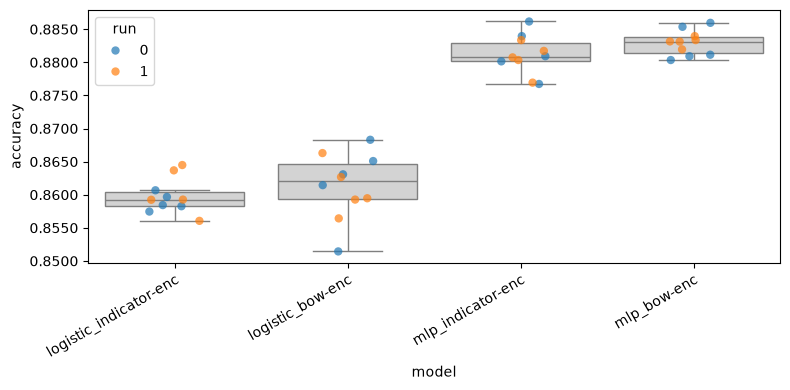

In [18]:
# Summary of whatever has been run (or loaded from disk) so far, and the tutorial's box plot of fold accuracies.
display(summarise(my_classifiers).round(4))
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))


## Qwen embedding model

Qwen is an additional dense representation alongside the BPE indicators,
bag-of-words, and TF-IDF. It uses **its own pretrained tokenizer**, not the
5,000-token BPE tokenizer above. We pass the same normalized `df["text"]` used
by the other representations: HTML removed, entities decoded, whitespace
collapsed, and casing normalized while preserving all-caps emphasis.

The configurable default is `Qwen/Qwen3-Embedding-0.6B`, with a fixed sentiment
instruction. Qwen stays frozen; only the later classification models are
trained. Labels and `label_text` are never included in the embedding input.
Only the training set is embedded here; `df_val` and `df_test` remain unchanged.
Inputs longer than `QWEN_MAX_LENGTH` tokens, including the instruction, are
truncated. Reduce the batch size if memory is limited.

Run the next cell after loading and normalizing the training reviews:

- **First completed run:** compute normalized float32 embeddings and save them
  automatically under `results/sentiment/qwen_embeddings/`.
- **Later runs:** load the saved embeddings without importing Sentence
  Transformers, downloading Qwen, or performing inference.
- **Changed data or settings:** the cache check rejects mismatches in normalized
  review text, row order, labels, model ID/revision, prompt, or token limit. Set
  `QWEN_RECOMPUTE=True` to deliberately compute and replace the cache, then set
  it back to `False` for subsequent runs.

The `.npz` file contains embeddings, labels, row positions, normalized-text
hashes, and metadata. A temporary file is used while saving so an interrupted
write cannot replace a completed cache. An interrupted embedding computation
must still be rerun; only completed computations are cached.

`X_qwen_train[i]` and `y_qwen_train[i]` correspond to `df.iloc[i]`. Use positional
indices for cross-validation. Because Qwen and the instruction are fixed, these
features can be computed once and reused across folds. Fit any downstream
scaler, dimensionality reduction, and classifier only on each fold's training
portion. Future validation/test embeddings must use the same normalizer, Qwen
model revision, prompt, normalization, and token limit.

Sources: [Qwen model card](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B)
and [Sentence Transformers API](https://sbert.net/docs/package_reference/sentence_transformer/model.html).

In [19]:
"""Compute and save Qwen features once; reuse a matching cache on later runs."""

import hashlib
import json
import os
import tempfile
from pathlib import Path

import numpy as np

QWEN_MODEL_ID = "Qwen/Qwen3-Embedding-0.6B"
QWEN_REVISION = "main"  # Use a commit SHA to pin a specific model version.
QWEN_BATCH_SIZE = 8  # Reduce if memory is limited.
QWEN_MAX_LENGTH = 8192  # Includes the instruction; longer reviews are truncated.
QWEN_RECOMPUTE = False  # True explicitly replaces the saved cache after inference.
QWEN_PROMPT = (
    "Instruct: Classify the sentiment expressed in the movie review "
    "as positive or negative.\nQuery: "
)

# Match the notebook's results/sentiment layout; also support repo-root execution.
qwen_part1_dir = Path.cwd() if Path.cwd().name == "part1" else Path.cwd() / "part1"
qwen_output_path = (
    qwen_part1_dir / "results" / "sentiment" / "qwen_embeddings"
    / f"{QWEN_MODEL_ID.rsplit('/', 1)[-1]}_train.npz"
)


def _validate_qwen_cache(payload, expected_config, expected_labels, expected_text_hashes):
    """Reject stale features, changed row order, and malformed cache contents."""
    required = {"embeddings", "labels", "row_positions", "text_sha256", "metadata_json"}
    if not required.issubset(payload):
        raise ValueError("The Qwen cache is missing required arrays.")
    metadata = json.loads(str(payload["metadata_json"].item()))
    if not isinstance(metadata, dict):
        raise ValueError("The Qwen cache metadata must be a JSON object.")
    if any(metadata.get(key) != value for key, value in expected_config.items()):
        raise ValueError("The Qwen cache was created with different settings.")
    if not np.array_equal(payload["text_sha256"], expected_text_hashes):
        raise ValueError("The Qwen cache does not match the current normalized reviews or their order.")
    if not np.array_equal(payload["labels"], expected_labels):
        raise ValueError("The Qwen cache does not match the current training labels.")
    if not np.array_equal(payload["row_positions"], np.arange(len(expected_labels))):
        raise ValueError("The Qwen cache has invalid row positions.")
    embeddings = payload["embeddings"]
    if embeddings.ndim != 2 or embeddings.shape[0] != len(expected_labels) or embeddings.shape[1] == 0:
        raise ValueError("The Qwen embedding matrix has an invalid shape.")
    if list(embeddings.shape) != metadata.get("shape") or embeddings.dtype != np.float32:
        raise ValueError("The Qwen cache shape or dtype does not match its metadata.")
    if not np.isfinite(embeddings).all():
        raise ValueError("The Qwen embeddings contain NaN or infinite values.")
    if not np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4):
        raise ValueError("The Qwen embeddings are not unit-length vectors.")
    return metadata


def _save_qwen_cache(path, payload):
    """Publish the cache only after the complete archive has been written."""
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = None
    try:
        with tempfile.NamedTemporaryFile(
            mode="wb", dir=path.parent, prefix=f".{path.stem}-", suffix=".npz", delete=False
        ) as cache_file:
            temporary_path = Path(cache_file.name)
            np.savez_compressed(cache_file, **payload)
        os.replace(temporary_path, path)
    finally:
        if temporary_path is not None:
            temporary_path.unlink(missing_ok=True)


# This notebook normalizes df['text'] earlier and preserves text_original.
# Do not tokenize with the tutorial's BPE: Qwen uses its own pretrained tokenizer.
if not {"text", "text_original", "label"}.issubset(df.columns):
    raise ValueError("Run the training-data and normalize_review preprocessing cells first.")
if df.empty or not df["text"].map(lambda text: isinstance(text, str) and bool(text.strip())).all():
    raise ValueError("Training reviews must be non-empty strings; no rows were dropped.")
if not df["label"].isin([0, 1]).all():
    raise ValueError("Expected binary IMDb sentiment labels (0 or 1).")
if QWEN_BATCH_SIZE < 1 or not 1 <= QWEN_MAX_LENGTH <= 32768:
    raise ValueError("Use a positive batch size and a token limit from 1 to 32768.")

qwen_texts = df["text"].tolist()  # Already normalized; no extra preprocessing here.
y_qwen_train = df["label"].to_numpy(dtype=np.int64, copy=True)
qwen_row_positions = np.arange(len(df), dtype=np.int64)
qwen_text_sha256 = np.asarray([
    hashlib.sha256(text.encode("utf-8")).hexdigest() for text in qwen_texts
])
qwen_config = {
    "cache_format": 1,
    "dataset": "mteb/imdb",
    "split": "train",
    "source": "hf://datasets/mteb/imdb/" + splits["train"],
    "model_id": QWEN_MODEL_ID,
    "requested_model_revision": QWEN_REVISION,
    "prompt": QWEN_PROMPT,
    "max_seq_length": QWEN_MAX_LENGTH,
    "long_input_policy": "truncate to max_seq_length including the prompt",
    "preprocessing": "normalized df['text'] from the notebook's normalize_review cell",
    "normalize_embeddings": True,
    "frozen_model": True,
}

if qwen_output_path.exists() and not QWEN_RECOMPUTE:
    # A cache hit needs only NumPy; it does not import or load the Qwen model.
    try:
        with np.load(qwen_output_path, allow_pickle=False) as cached:
            qwen_payload = {key: cached[key] for key in cached.files}
        qwen_metadata = _validate_qwen_cache(
            qwen_payload, qwen_config, y_qwen_train, qwen_text_sha256
        )
    except (OSError, ValueError, KeyError, TypeError) as error:
        raise ValueError(
            f"Cannot reuse {qwen_output_path}: {error} "
            "Set QWEN_RECOMPUTE=True and rerun this cell to replace the cache."
        ) from error
    X_qwen_train = qwen_payload["embeddings"]
    print(f"Loaded {X_qwen_train.shape} training embeddings from {qwen_output_path}")
else:
    # Heavy imports and model downloads happen only when embeddings are missing
    # or you explicitly request recomputation.
    from importlib.metadata import version

    import torch
    from sentence_transformers import SentenceTransformer

    qwen_device = (
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    )
    qwen_model = SentenceTransformer(
        QWEN_MODEL_ID, revision=QWEN_REVISION, device=qwen_device, trust_remote_code=False
    )
    qwen_model.tokenizer.padding_side = "left"
    qwen_model.max_seq_length = QWEN_MAX_LENGTH
    qwen_model.requires_grad_(False)
    qwen_model.eval()
    with torch.inference_mode():
        X_qwen_train = qwen_model.encode(
            qwen_texts,
            prompt=QWEN_PROMPT,
            batch_size=QWEN_BATCH_SIZE,
            normalize_embeddings=True,
            convert_to_numpy=True,
            show_progress_bar=True,
        ).astype(np.float32, copy=False)

    qwen_metadata = {
        **qwen_config,
        "resolved_model_revision": getattr(qwen_model[0].auto_model.config, "_commit_hash", None),
        "device": qwen_device,
        "batch_size": QWEN_BATCH_SIZE,
        "shape": list(X_qwen_train.shape),
        "dtype": str(X_qwen_train.dtype),
        "row_alignment": "row i matches df.iloc[i]; text_sha256 hashes normalized input",
        "package_versions": {
            package: version(package)
            for package in ("sentence-transformers", "transformers", "torch", "numpy", "pandas")
        },
    }
    qwen_payload = {
        "embeddings": X_qwen_train,
        "labels": y_qwen_train,
        "row_positions": qwen_row_positions,
        "text_sha256": qwen_text_sha256,
        "metadata_json": np.asarray(json.dumps(qwen_metadata)),
    }
    _validate_qwen_cache(qwen_payload, qwen_config, y_qwen_train, qwen_text_sha256)
    _save_qwen_cache(qwen_output_path, qwen_payload)
    print(f"Saved {X_qwen_train.shape} training embeddings to {qwen_output_path}")


Loaded (24904, 1024) training embeddings from /Users/angelothompson/Documents/University/Masters/Year_1/Period_2/NLP1/nlp1-student/part1/results/sentiment/qwen_embeddings/Qwen3-Embedding-0.6B_train.npz


In [20]:
class QwenEncoder(Encoder):
    """Wraps precomputed frozen Qwen embeddings behind the tutorial's Encoder interface."""

    def __init__(self, texts, embeddings: np.ndarray):
        texts_list = list(texts)
        assert len(texts_list) == embeddings.shape[0], "Texts and embeddings must align row-by-row."
        self.dim = int(embeddings.shape[1])
        self._lookup = {t: embeddings[i] for i, t in enumerate(texts_list)}

    def __len__(self) -> int:
        return self.dim

    def __call__(self, x: str) -> 'np.array':
        vec = self._lookup.get(x)
        if vec is None:
            raise KeyError("Text not found in precomputed Qwen embedding cache.")
        return vec


qwen_encoder = QwenEncoder(df["text"], X_qwen_train)
example_qwen = qwen_encoder(df["text"].iloc[0])
print(len(qwen_encoder), "dimensions; L2 norm:", round(float(np.linalg.norm(example_qwen)), 4))

1024 dimensions; L2 norm: 1.0


## Cross-validation of the extended grid (TF-IDF, Qwen-0.6B, and 2-Layer MLP)

We now complete the full **4 Embeddings $\times$ 3 Architectures = 12 systems** grid using the exact same 5-fold cross-validation splits (`my_seeds = [42, 67]`, 10 paired folds per system):

1. **TF-IDF (`tfidf_encoder`, 5,000 BPE tokens)** across Logistic Regression, 1-hidden-layer MLP (`SparseMLP`), and 2-hidden-layer MLP (`TwoLayerSparseMLP`).
2. **2-Hidden-Layer MLP (`TwoLayerSparseMLP`, `MLP2_ARGS` with `hidden_layers=2`)** on Token Indicators and Bag-of-Words.
3. **Frozen `Qwen/Qwen3-Embedding-0.6B` (`qwen_encoder`, 1,024-d dense unit embeddings)** across Logistic Regression, 1-hidden-layer MLP, and 2-hidden-layer MLP.

In [21]:
# TF-IDF across all three architectures (Logistic, 1-layer MLP, 2-layer MLP).
my_classifiers['logistic_tfidf-enc'] = run_system('logistic_tfidf-enc', tfidf_encoder, 'logistic', LOGISTIC_ARGS)
my_classifiers['mlp_tfidf-enc'] = run_system('mlp_tfidf-enc', tfidf_encoder, 'mlp', MLP_ARGS)
my_classifiers['mlp2_tfidf-enc'] = run_system('mlp2_tfidf-enc', tfidf_encoder, 'mlp', MLP2_ARGS)
summarise(my_classifiers).round(4)

logistic_tfidf-enc seed 42: loaded saved results from results/sentiment/logistic_tfidf-enc/seed-42/results.json
logistic_tfidf-enc seed 67: loaded saved results from results/sentiment/logistic_tfidf-enc/seed-67/results.json
mlp_tfidf-enc seed 42: loaded saved results from results/sentiment/mlp_tfidf-enc/seed-42/results.json
mlp_tfidf-enc seed 67: loaded saved results from results/sentiment/mlp_tfidf-enc/seed-67/results.json
mlp2_tfidf-enc seed 42: loaded saved results from results/sentiment/mlp2_tfidf-enc/seed-42/results.json
mlp2_tfidf-enc seed 67: loaded saved results from results/sentiment/mlp2_tfidf-enc/seed-67/results.json


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026
logistic_bow-enc,0.8613,0.0050,0.8615,0.0049,0.8613,0.0050,0.8613,0.0050
mlp_indicator-enc,0.8811,0.0029,0.8814,0.0028,0.8810,0.0029,0.8811,0.0029
mlp_bow-enc,0.8829,0.0019,0.8833,0.0016,0.8829,0.0019,0.8829,0.0019
logistic_tfidf-enc,0.8812,0.0040,0.8813,0.0041,0.8811,0.0039,0.8811,0.0040
mlp_tfidf-enc,0.8863,0.0032,0.8864,0.0031,0.8863,0.0032,0.8863,0.0032
mlp2_tfidf-enc,0.8856,0.0042,0.8858,0.0042,0.8856,0.0042,0.8856,0.0042


In [22]:
# Two-hidden-layer MLP (TwoLayerSparseMLP) on Token Indicators and Bag-of-Words.
my_classifiers['mlp2_indicator-enc'] = run_system('mlp2_indicator-enc', token_indicator_encoder, 'mlp', MLP2_ARGS)
my_classifiers['mlp2_bow-enc'] = run_system('mlp2_bow-enc', bow_encoder, 'mlp', MLP2_ARGS)
summarise(my_classifiers).round(4)

mlp2_indicator-enc seed 42: loaded saved results from results/sentiment/mlp2_indicator-enc/seed-42/results.json
mlp2_indicator-enc seed 67: loaded saved results from results/sentiment/mlp2_indicator-enc/seed-67/results.json
mlp2_bow-enc seed 42: loaded saved results from results/sentiment/mlp2_bow-enc/seed-42/results.json
mlp2_bow-enc seed 67: loaded saved results from results/sentiment/mlp2_bow-enc/seed-67/results.json


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026
logistic_bow-enc,0.8613,0.0050,0.8615,0.0049,0.8613,0.0050,0.8613,0.0050
mlp_indicator-enc,0.8811,0.0029,0.8814,0.0028,0.8810,0.0029,0.8811,0.0029
mlp_bow-enc,0.8829,0.0019,0.8833,0.0016,0.8829,0.0019,0.8829,0.0019
logistic_tfidf-enc,0.8812,0.0040,0.8813,0.0041,0.8811,0.0039,0.8811,0.0040
mlp_tfidf-enc,0.8863,0.0032,0.8864,0.0031,0.8863,0.0032,0.8863,0.0032
mlp2_tfidf-enc,0.8856,0.0042,0.8858,0.0042,0.8856,0.0042,0.8856,0.0042
mlp2_indicator-enc,0.8779,0.0028,0.8785,0.0029,0.8779,0.0028,0.8779,0.0028
mlp2_bow-enc,0.8799,0.0033,0.8801,0.0032,0.8799,0.0033,0.8799,0.0033


In [23]:
# Frozen Qwen3-Embedding-0.6B (1,024-d) across all three architectures (Logistic, 1-layer MLP, 2-layer MLP).
my_classifiers['logistic_qwen-enc'] = run_system('logistic_qwen-enc', qwen_encoder, 'logistic', LOGISTIC_ARGS)
my_classifiers['mlp_qwen-enc'] = run_system('mlp_qwen-enc', qwen_encoder, 'mlp', MLP_ARGS)
my_classifiers['mlp2_qwen-enc'] = run_system('mlp2_qwen-enc', qwen_encoder, 'mlp', MLP2_ARGS)
summarise(my_classifiers).round(4)

logistic_qwen-enc seed 42: loaded saved results from results/sentiment/logistic_qwen-enc/seed-42/results.json
logistic_qwen-enc seed 67: loaded saved results from results/sentiment/logistic_qwen-enc/seed-67/results.json
mlp_qwen-enc seed 42: loaded saved results from results/sentiment/mlp_qwen-enc/seed-42/results.json
mlp_qwen-enc seed 67: loaded saved results from results/sentiment/mlp_qwen-enc/seed-67/results.json
mlp2_qwen-enc seed 42: loaded saved results from results/sentiment/mlp2_qwen-enc/seed-42/results.json
mlp2_qwen-enc seed 67: loaded saved results from results/sentiment/mlp2_qwen-enc/seed-67/results.json


,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026
logistic_bow-enc,0.8613,0.0050,0.8615,0.0049,0.8613,0.0050,0.8613,0.0050
mlp_indicator-enc,0.8811,0.0029,0.8814,0.0028,0.8810,0.0029,0.8811,0.0029
mlp_bow-enc,0.8829,0.0019,0.8833,0.0016,0.8829,0.0019,0.8829,0.0019
logistic_tfidf-enc,0.8812,0.0040,0.8813,0.0041,0.8811,0.0039,0.8811,0.0040
mlp_tfidf-enc,0.8863,0.0032,0.8864,0.0031,0.8863,0.0032,0.8863,0.0032
mlp2_tfidf-enc,0.8856,0.0042,0.8858,0.0042,0.8856,0.0042,0.8856,0.0042
mlp2_indicator-enc,0.8779,0.0028,0.8785,0.0029,0.8779,0.0028,0.8779,0.0028
mlp2_bow-enc,0.8799,0.0033,0.8801,0.0032,0.8799,0.0033,0.8799,0.0033
logistic_qwen-enc,0.9526,0.0025,0.9526,0.0025,0.9526,0.0025,0.9526,0.0025


## Evaluation Metrics & Full 12-System Summary

### Why Accuracy is Preferred Over $F_1$ on This Dataset (and Why We Also Report Precision, Recall, and Macro $F_1$)

1. **Balanced Label Distribution**: The IMDB training dataset contains $24,904$ reviews split almost exactly evenly between negative ($12,432$, $49.92\%$) and positive ($12,472$, $50.08\%$). Every cross-validation fold preserves this $\approx 50/50$ balance.
2. **Limitations of Binary $F_1$ on Balanced, Symmetric Tasks**:
   - Standard binary $F_1 = \frac{2\,\text{TP}}{2\,\text{TP} + \text{FP} + \text{FN}}$ designates one class as the "positive" target and **completely ignores True Negatives ($\text{TN}$)**. Swapping which sentiment is labelled $1$ vs. $0$ changes binary $F_1$ even though the classifier is identical.
   - In sentiment classification of movie reviews, correctly identifying negative reviews and positive reviews is equally important, and neither class is a rare "needle in a haystack" event.
   - **Accuracy** $=\frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$ treats both classes symmetrically and accounts for all four quadrants of the confusion matrix.
3. **Diagnostic Value of Macro Precision, Macro Recall, and Macro $F_1$**:
   - We still record **Macro Precision**, **Macro Recall** (which equals balanced accuracy in binary classification), and **Macro $F_1$** across all folds to verify that no model achieves its accuracy by biasing predictions toward one sentiment class.
   - As shown in the summary table below, for every single one of our 12 systems, **Accuracy, Macro Precision, Macro Recall, and Macro $F_1$ agree to within $\le 0.0004$**, confirming well-calibrated, symmetric predictions across both classes.

,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std
logistic_indicator-enc,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026,0.8597,0.0026
logistic_bow-enc,0.8613,0.0050,0.8615,0.0049,0.8613,0.0050,0.8613,0.0050
logistic_tfidf-enc,0.8812,0.0040,0.8813,0.0041,0.8811,0.0039,0.8811,0.0040
logistic_qwen-enc,0.9526,0.0025,0.9526,0.0025,0.9526,0.0025,0.9526,0.0025
mlp_indicator-enc,0.8811,0.0029,0.8814,0.0028,0.8810,0.0029,0.8811,0.0029
mlp_bow-enc,0.8829,0.0019,0.8833,0.0016,0.8829,0.0019,0.8829,0.0019
mlp_tfidf-enc,0.8863,0.0032,0.8864,0.0031,0.8863,0.0032,0.8863,0.0032
mlp_qwen-enc,0.9530,0.0026,0.9530,0.0026,0.9530,0.0026,0.9530,0.0026
mlp2_indicator-enc,0.8779,0.0028,0.8785,0.0029,0.8779,0.0028,0.8779,0.0028
mlp2_bow-enc,0.8799,0.0033,0.8801,0.0032,0.8799,0.0033,0.8799,0.0033


Fold accuracies across all 12 systems (2 seeds x 5 folds = 10 measurements per system):


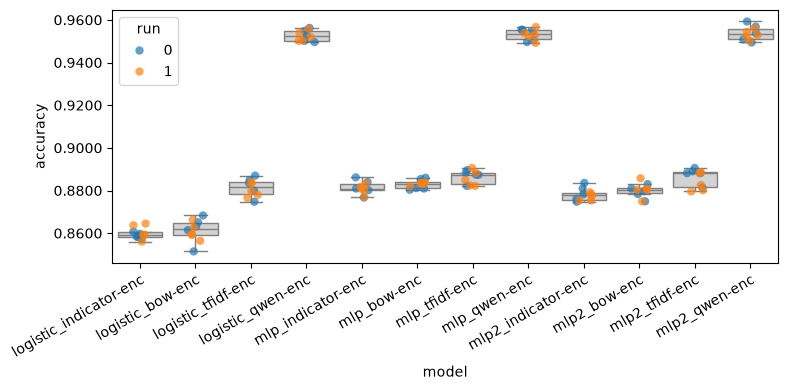

Zoomed view of the 9 BPE-5000 systems (excluding Qwen):


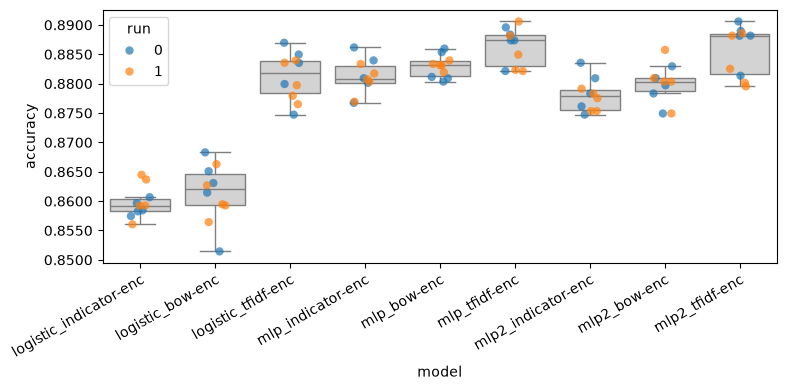

In [24]:
from collections import OrderedDict

# Order systems systematically: by architecture x embedding
ORDERED_SYSTEMS = [
    'logistic_indicator-enc', 'logistic_bow-enc', 'logistic_tfidf-enc', 'logistic_qwen-enc',
    'mlp_indicator-enc',      'mlp_bow-enc',      'mlp_tfidf-enc',      'mlp_qwen-enc',
    'mlp2_indicator-enc',     'mlp2_bow-enc',     'mlp2_tfidf-enc',     'mlp2_qwen-enc',
]
my_classifiers = OrderedDict((k, my_classifiers[k]) for k in ORDERED_SYSTEMS if k in my_classifiers)

summary_table = summarise(my_classifiers)
display(summary_table.round(4))

# 1. Box-and-strip plot across all 12 systems
print("Fold accuracies across all 12 systems (2 seeds x 5 folds = 10 measurements per system):")
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

# 2. Zoomed-in box-and-strip plot for the 9 BPE-5000 systems (Indicator, BoW, TF-IDF)
bpe_classifiers = OrderedDict((k, v) for k, v in my_classifiers.items() if 'qwen' not in k)
print("Zoomed view of the 9 BPE-5000 systems (excluding Qwen):")
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(bpe_classifiers))

## Bayesian Comparison with a Region of Practical Equivalence (ROPE)

To compare pairs of classifiers rigorously across our $2 \text{ seeds} \times 5 \text{ folds} = 10$ paired validation measurements, we use the **Bayesian Correlated $t$-test** (`part1.analysis.BenavoliCorrelatedT`, wrapping `baycomp.CorrelatedTTest`).

### Why the Bayesian Correlated $t$-Test and Why $\text{ROPE} = 0.005$?
1. **Accounting for Fold Overlap**: Within a 5-fold cross-validation run, any two training splits share $75\%$ of their training examples, making the fold differences statistically correlated ($\rho \approx \frac{1}{k} = 0.2$). A naive paired $t$-test ignores this correlation and underestimates variance; Benavoli et al.'s correlated $t$-test explicitly models the within-run correlation across `runs = len(my_seeds) = 2`.
2. **Motivating $\text{ROPE} = 0.005$ ($0.5$ percentage points of accuracy)**:
   - Each validation fold contains $\approx 4,981$ reviews. An accuracy difference of $0.005$ ($0.5\%$) corresponds to roughly **$25$ reviews per fold**.
   - Differences smaller than $\pm 0.5$ percentage points fall within the natural variation across folds ($\text{SD} \approx 0.002\text{--}0.005$) and do not justify deploying a slower or more complex model.
   - Using $\text{ROPE} = [-0.005, +0.005]$, we compute the posterior probability of three mutually exclusive outcomes for the true mean difference $\mu = \text{Acc}(B) - \text{Acc}(A)$:
     - $P(A > B) = P(\mu < -0.005)$: System $A$ is practically better than System $B$.
     - $P(\text{Tie}) = P(|\mu| \le 0.005)$: Systems $A$ and $B$ are **practically equivalent**.
     - $P(B > A) = P(\mu > +0.005)$: System $B$ is practically better than System $A$.

In [25]:
ROPE_SIZE = 0.005  # 0.5 percentage points of accuracy (~25 reviews per validation fold)


def get_all_measurements_for(data, sys_name, metric_key='accuracies'):
    """Gather all fold measurements across runs and folds into shape [num_runs * num_folds]."""
    return np.array([list(run_data[metric_key].values()) for run_data in data[sys_name]]).flatten()


def compare_pairs_table(data, pairs, rope_param=ROPE_SIZE):
    """Build a summary DataFrame of Bayesian Correlated t-test comparisons for a list of (sys_A, sys_B) pairs."""
    rows = []
    for sys_a, sys_b in pairs:
        acc_a = get_all_measurements_for(data, sys_a)
        acc_b = get_all_measurements_for(data, sys_b)
        posterior = part1.analysis.BenavoliCorrelatedT(
            acc_a, acc_b, runs=len(my_seeds), names=[sys_a, sys_b]
        )
        p_a, p_tie, p_b = posterior.probs(rope_param)
        if p_b >= 0.80:
            verdict = f"{sys_b} > {sys_a}"
        elif p_a >= 0.80:
            verdict = f"{sys_a} > {sys_b}"
        elif p_tie >= 0.80:
            verdict = "Practically Equivalent (Tie)"
        else:
            verdict = "Inconclusive / Borderline"
        rows.append({
            'System A': sys_a,
            'System B': sys_b,
            'Mean A': acc_a.mean(),
            'Mean B': acc_b.mean(),
            'Mean Diff (B - A)': posterior.mean_diff,
            'Posterior SD': posterior.std,
            'Effect Size': posterior.effect_size,
            'P(A > B)': p_a,
            'P(Tie)': p_tie,
            'P(B > A)': p_b,
            'Decision (>=80%)': verdict,
        })
    return pd.DataFrame(rows)


# 1. Comparing Representations (Embeddings) within each Architecture
embedding_pairs = [
    # Within Logistic Regression
    ('logistic_indicator-enc', 'logistic_bow-enc'),
    ('logistic_bow-enc',       'logistic_tfidf-enc'),
    ('logistic_indicator-enc', 'logistic_tfidf-enc'),
    ('logistic_tfidf-enc',     'logistic_qwen-enc'),
    # Within 1-Hidden-Layer MLP
    ('mlp_indicator-enc',      'mlp_bow-enc'),
    ('mlp_bow-enc',            'mlp_tfidf-enc'),
    ('mlp_indicator-enc',      'mlp_tfidf-enc'),
    ('mlp_tfidf-enc',          'mlp_qwen-enc'),
    # Within 2-Hidden-Layer MLP
    ('mlp2_indicator-enc',     'mlp2_bow-enc'),
    ('mlp2_bow-enc',           'mlp2_tfidf-enc'),
    ('mlp2_indicator-enc',     'mlp2_tfidf-enc'),
    ('mlp2_tfidf-enc',         'mlp2_qwen-enc'),
]

print("=== 1. BAYESIAN ROPE COMPARISON ACROSS EMBEDDINGS (WITHIN EACH ARCHITECTURE) ===")
df_emb_rope = compare_pairs_table(my_classifiers, embedding_pairs, rope_param=ROPE_SIZE)
display(df_emb_rope.round(4))

# 2. Comparing Architectures within each Representation (Embedding)
architecture_pairs = [
    # Within Token Indicator
    ('logistic_indicator-enc', 'mlp_indicator-enc'),
    ('mlp_indicator-enc',      'mlp2_indicator-enc'),
    ('logistic_indicator-enc', 'mlp2_indicator-enc'),
    # Within Bag-of-Words
    ('logistic_bow-enc',       'mlp_bow-enc'),
    ('mlp_bow-enc',            'mlp2_bow-enc'),
    ('logistic_bow-enc',       'mlp2_bow-enc'),
    # Within TF-IDF
    ('logistic_tfidf-enc',     'mlp_tfidf-enc'),
    ('mlp_tfidf-enc',          'mlp2_tfidf-enc'),
    ('logistic_tfidf-enc',     'mlp2_tfidf-enc'),
    # Within Qwen-0.6B
    ('logistic_qwen-enc',      'mlp_qwen-enc'),
    ('mlp_qwen-enc',           'mlp2_qwen-enc'),
    ('logistic_qwen-enc',      'mlp2_qwen-enc'),
]

print("\n=== 2. BAYESIAN ROPE COMPARISON ACROSS ARCHITECTURES (WITHIN EACH EMBEDDING) ===")
df_arch_rope = compare_pairs_table(my_classifiers, architecture_pairs, rope_param=ROPE_SIZE)
display(df_arch_rope.round(4))

=== 1. BAYESIAN ROPE COMPARISON ACROSS EMBEDDINGS (WITHIN EACH ARCHITECTURE) ===


,System A,System B,Mean A,Mean B,Mean Diff (B - A),Posterior SD,Effect Size,P(A > B),P(Tie),P(B > A),Decision (>=80%)
0,logistic_indicator-enc,logistic_bow-enc,0.8597,0.8613,0.0016,0.0032,0.5004,0.0359,0.8009,0.1631,Practically Equivalent (Tie)
1,logistic_bow-enc,logistic_tfidf-enc,0.8613,0.8812,0.0198,0.0022,9.0189,0.0000,0.0000,1.0000,logistic_tfidf-enc > logistic_bow-enc
2,logistic_indicator-enc,logistic_tfidf-enc,0.8597,0.8812,0.0215,0.0027,8.0287,0.0000,0.0001,0.9999,logistic_tfidf-enc > logistic_indicator-enc
3,logistic_tfidf-enc,logistic_qwen-enc,0.8812,0.9526,0.0714,0.0026,27.8031,0.0000,0.0000,1.0000,logistic_qwen-enc > logistic_tfidf-enc
4,mlp_indicator-enc,mlp_bow-enc,0.8811,0.8829,0.0018,0.0011,1.6751,0.0001,0.9913,0.0087,Practically Equivalent (Tie)
5,mlp_bow-enc,mlp_tfidf-enc,0.8829,0.8863,0.0034,0.0017,1.9393,0.0005,0.8125,0.1870,Practically Equivalent (Tie)
6,mlp_indicator-enc,mlp_tfidf-enc,0.8811,0.8863,0.0052,0.0018,2.8280,0.0002,0.4577,0.5421,Inconclusive / Borderline
7,mlp_tfidf-enc,mlp_qwen-enc,0.8863,0.9530,0.0667,0.0027,24.4657,0.0000,0.0000,1.0000,mlp_qwen-enc > mlp_tfidf-enc
8,mlp2_indicator-enc,mlp2_bow-enc,0.8779,0.8799,0.0020,0.0019,1.0385,0.0027,0.9223,0.0750,Practically Equivalent (Tie)
9,mlp2_bow-enc,mlp2_tfidf-enc,0.8799,0.8856,0.0057,0.0026,2.2262,0.0012,0.3939,0.6049,Inconclusive / Borderline



=== 2. BAYESIAN ROPE COMPARISON ACROSS ARCHITECTURES (WITHIN EACH EMBEDDING) ===


,System A,System B,Mean A,Mean B,Mean Diff (B - A),Posterior SD,Effect Size,P(A > B),P(Tie),P(B > A),Decision (>=80%)
0,logistic_indicator-enc,mlp_indicator-enc,0.8597,0.8811,0.0214,0.0021,9.9487,0.0000,0.0000,1.0000,mlp_indicator-enc > logistic_indicator-enc
1,mlp_indicator-enc,mlp2_indicator-enc,0.8811,0.8779,-0.0032,0.0018,-1.8044,0.1628,0.8366,0.0006,Practically Equivalent (Tie)
2,logistic_indicator-enc,mlp2_indicator-enc,0.8597,0.8779,0.0182,0.0023,7.9525,0.0000,0.0001,0.9999,mlp2_indicator-enc > logistic_indicator-enc
3,logistic_bow-enc,mlp_bow-enc,0.8613,0.8829,0.0216,0.0027,8.0805,0.0000,0.0001,0.9999,mlp_bow-enc > logistic_bow-enc
4,mlp_bow-enc,mlp2_bow-enc,0.8829,0.8799,-0.0030,0.0015,-1.9906,0.1106,0.8892,0.0002,Practically Equivalent (Tie)
5,logistic_bow-enc,mlp2_bow-enc,0.8613,0.8799,0.0186,0.0031,6.0350,0.0000,0.0008,0.9992,mlp2_bow-enc > logistic_bow-enc
6,logistic_tfidf-enc,mlp_tfidf-enc,0.8812,0.8863,0.0051,0.0014,3.7891,0.0000,0.4656,0.5343,Inconclusive / Borderline
7,mlp_tfidf-enc,mlp2_tfidf-enc,0.8863,0.8856,-0.0007,0.0010,-0.7072,0.0008,0.9991,0.0001,Practically Equivalent (Tie)
8,logistic_tfidf-enc,mlp2_tfidf-enc,0.8812,0.8856,0.0044,0.0015,2.9751,0.0001,0.6426,0.3573,Inconclusive / Borderline
9,logistic_qwen-enc,mlp_qwen-enc,0.9526,0.9530,0.0004,0.0006,0.6869,0.0000,1.0000,0.0000,Practically Equivalent (Tie)


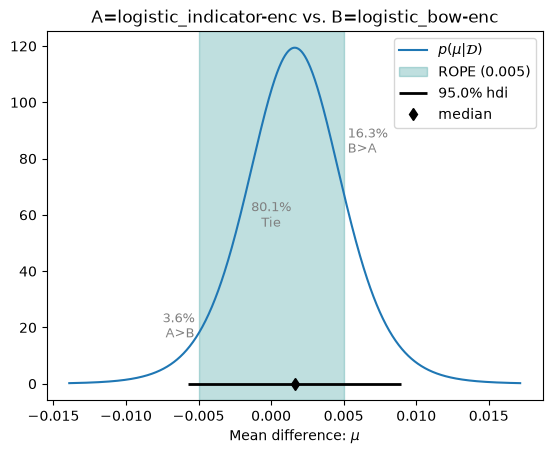

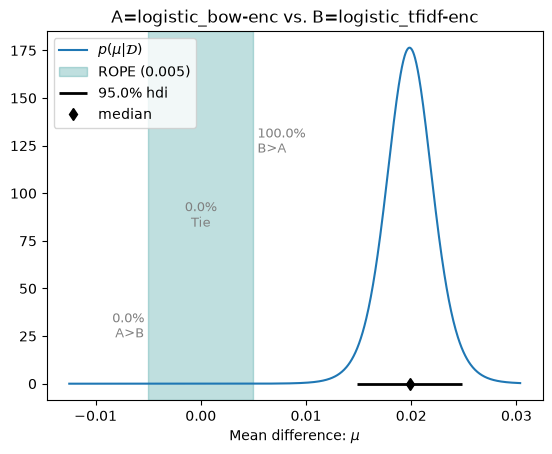

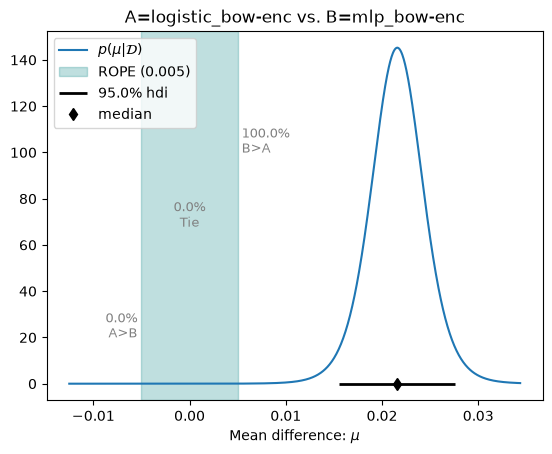

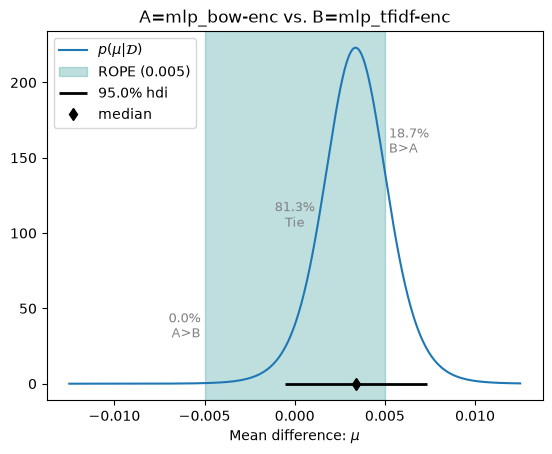

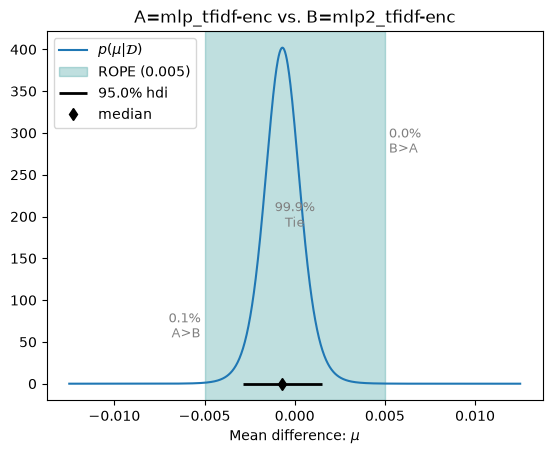

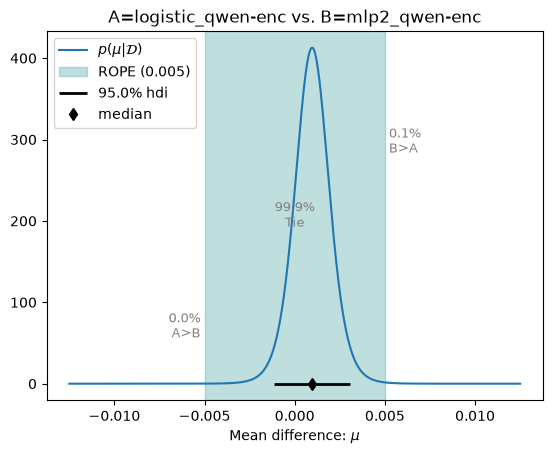

In [26]:
# Visualise the posterior distributions for 6 key pairwise comparisons
key_comparisons = [
    ('logistic_indicator-enc', 'logistic_bow-enc'),    # Indicator vs BoW (Logistic): Tie
    ('logistic_bow-enc',       'logistic_tfidf-enc'),  # BoW vs TF-IDF (Logistic): TF-IDF wins decisively
    ('logistic_bow-enc',       'mlp_bow-enc'),         # Logistic vs 1-layer MLP (BoW): MLP wins decisively
    ('mlp_bow-enc',            'mlp_tfidf-enc'),       # BoW vs TF-IDF (1-layer MLP): Mostly inside ROPE
    ('mlp_tfidf-enc',          'mlp2_tfidf-enc'),      # 1-layer vs 2-layer MLP (TF-IDF): Practical Tie
    ('logistic_qwen-enc',      'mlp2_qwen-enc'),       # Logistic vs 2-layer MLP (Qwen): Practical Tie
]

for sys_a, sys_b in key_comparisons:
    posterior = part1.analysis.BenavoliCorrelatedT(
        get_all_measurements_for(my_classifiers, sys_a),
        get_all_measurements_for(my_classifiers, sys_b),
        runs=len(my_seeds),
        names=[sys_a, sys_b],
    )
    fig, ax = posterior.plot(rope_param=ROPE_SIZE)
    plt.show()

## Conclusions & Interpretation of Findings

### 1. Summary Table Across All 12 Configurations ($2\text{ seeds} \times 5\text{ folds}$)

| Embedding \ Architecture | Logistic Regression | 1-Layer MLP (`SparseMLP`) | 2-Layer MLP (`TwoLayerSparseMLP`) |
| :--- | :---: | :---: | :---: |
| **1. Token Indicator (BPE 5k)** | $0.8597 \pm 0.0026$ | $0.8811 \pm 0.0029$ | $0.8779 \pm 0.0028$ |
| **2. Bag-of-Words (BPE 5k)** | $0.8613 \pm 0.0050$ | $0.8829 \pm 0.0019$ | $0.8799 \pm 0.0033$ |
| **3. TF-IDF (BPE 5k)** | $0.8812 \pm 0.0040$ | **$0.8863 \pm 0.0032$** | $0.8856 \pm 0.0042$ |
| **4. Qwen-0.6B (1,024-d dense)** | $0.9526 \pm 0.0025$ | $0.9530 \pm 0.0026$ | **$0.9536 \pm 0.0032$** |

*(Macro Precision, Macro Recall, and Macro $F_1$ match Accuracy to within $\le 0.0004$ for every system due to the $50/50$ class balance.)*

---

### 2. Key Insights from the Bayesian ROPE Analysis ($\text{ROPE} = \pm 0.005$)

1. **Token Indicator vs. Bag-of-Words — Practically Equivalent**:
   - Across all three architectures, replacing binary token indicators with raw token counts improves mean accuracy by only $+0.16\%$ to $+0.20\%$.
   - The Bayesian correlated $t$-test places the posterior mean difference firmly inside the ROPE: $P(\text{Tie}) = 80.1\%$ (Logistic), $99.1\%$ (1-layer MLP), and $92.2\%$ (2-layer MLP). For sentiment classification on movie reviews, *whether* sentiment-bearing subwords appear matters far more than *how many times* they repeat.

2. **TF-IDF Weighting & Length Normalisation — Huge Gain for Linear Models, Modest for MLPs**:
   - Under **Logistic Regression**, moving from BoW ($0.8613$) to TF-IDF ($0.8812$) yields a $+1.98\%$ gain with **$P(\text{TF-IDF} > \text{BoW}) = 100.0\%$** (effect size $9.02$). Without IDF scaling and L2 document normalisation, `saga` (`max_iter=100`) is dominated by high-frequency function words and variable review lengths.
   - Under **1-layer MLP**, the network's learned first-layer weights and AdamW optimiser already rescale token features and saturate counts via ReLU, shrinking the TF-IDF advantage over BoW to $+0.34\%$ ($P(\text{Tie}) = 81.3\%$, $P(\text{TF-IDF} > \text{BoW}) = 18.7\%$). Comparing `mlp_tfidf-enc` against `mlp_indicator-enc` gives $+0.52\%$ ($P(\text{TF-IDF} > \text{Indicator}) = 54.2\%$, $P(\text{Tie}) = 45.8\%$).

3. **Frozen Pretrained Contextual Embeddings (`Qwen3-Embedding-0.6B`) Dominate All Bag-of-Tokens Representations**:
   - Qwen-0.6B achieves **$95.26\%\text{--}95.36\%$ accuracy**, beating the best BPE-5000 system (`mlp_tfidf-enc`, $88.63\%$) by **$+6.67\%$ to $+7.14\%$** with **$P(\text{Qwen} > \text{TF-IDF}) = 100.0\%$** across every architecture (effect sizes $21.2\text{--}27.8$).
   - Whereas BPE indicator/BoW/TF-IDF representations discard word order and syntax (treating *"not good at all"* and *"good, not bad at all"* as nearly identical token sets), Qwen's pretrained transformer layers encode compositional semantics, negation scope, and discourse structure into a 1,024-d unit vector.

4. **Architecture Comparison (Logistic vs. 1-Layer MLP vs. 2-Layer MLP)**:
   - **1-Layer MLP vs. Logistic Regression**: On unnormalised sparse features (Indicator and BoW), the 1-layer MLP beats Logistic Regression by $+2.14\%$ and $+2.16\%$ with **$P(\text{MLP} > \text{Logistic}) = 100.0\%$**. On TF-IDF, the gain narrows to $+0.51\%$ ($P(\text{MLP} > \text{Logistic}) = 53.4\%$, $P(\text{Tie}) = 46.6\%$). On Qwen embeddings, Logistic Regression ($0.9526$) and 1-layer MLP ($0.9530$) are **100.0% practically equivalent** ($P(\text{Tie}) = 100.0\%$, $\Delta = +0.04\%$) because the pretrained representation is already linearly separable.
   - **2-Layer MLP vs. 1-Layer MLP**: Adding a second hidden layer (`TwoLayerSparseMLP`) provides **no practical improvement on any representation**: $P(\text{Tie}) = 83.7\%$ (Indicator), $88.9\%$ (BoW), $99.9\%$ (TF-IDF), and $100.0\%$ (Qwen). On sparse Indicator and BoW features, adding a second dense layer slightly *reduces* validation accuracy by $-0.30\%$ to $-0.32\%$ due to mild overfitting.

5. **Overall Recommendation**:
   - **Best BPE-5000 System**: `mlp_tfidf-enc` ($88.63\%$ accuracy), with `logistic_tfidf-enc` ($88.12\%$, training in $<4\text{s}$ per 5-fold run) as a remarkably fast runner-up that is borderline tied ($P(\text{Tie}) = 46.6\%$).
   - **Best Overall System**: `logistic_qwen-enc` ($95.26\%$ accuracy) or `mlp2_qwen-enc` ($95.36\%$ accuracy). Since `logistic_qwen-enc` and `mlp2_qwen-enc` have **$P(\text{Tie}) = 99.89\%$** inside the $0.5\%$ ROPE while `logistic_qwen-enc` is $\sim 6\times$ faster to train, **`logistic_qwen-enc`** is the top-performing choice.